# Notatnik 10b — operacyjny dobór progu alarmowego (walk-forward)

Cel: ograniczyć stały alarm modeli LPPLS+ML przy kontrolowanym kompromisie między
odsetkiem wykrytych zdarzeń, fałszywymi nowymi ostrzeżeniami i czasem w stanie alarmowym.

**Metodologia:** wyłącznie OOS `score` z 08b. Dla testu 2022 kalibracja na OOS 2021,
dla 2023 na OOS 2021–2022, dla 2024 na OOS 2021–2023.
Na końcu każdej kalibracji wykluczamy H dni (znajomość wyników do daty testu).
Dla roku 2021 nie ma wcześniejszych prognoz OOS w pliku 08b — porównujemy go tylko
z progami z góry określonymi, nie przypisujemy mu progu zoptymalizowanego.

To **analiza eksploracyjna**: lata 2021–2024 były wcześniej oglądane, więc nie są
niezależnym finalnym testem. Miary event-based dotyczą osobnego zadania (przekroczenia
drawdown 10% od maksimum z ostatnich 180 dni), a nie etykiety future_drop z 07.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import confusion_matrix, average_precision_score

ROOT = Path('.')
OUT = ROOT / 'wyniki_threshold_10b'
OUT.mkdir(exist_ok=True, parents=True)

PRED_CANDIDATES = [
    ROOT/'wyniki_tuning_08b'/'08b_04_predykcje_OOS.csv',
    ROOT/'08b_04_predykcje_OOS.csv',
]
PRICE_CANDIDATES = [
    ROOT/'wyniki_future_drop_07'/'lppls_future_drop_dataset.csv',
    ROOT/'lppls_future_drop_dataset.csv',
    ROOT/'btc_usd_2015_2024.csv',
]

TARGET_CONFIGS = [(10, 60)]  # rozszerz później do 9 konfiguracji
MODEL_NAMES = ['LogisticRegression','XGBoost','LightGBM']
FEATURE_GROUPS = ['Price-only','LPPLS-only','Price+LPPLS']
TEST_YEARS = [2022, 2023, 2024]
HISTORICAL_OOS_START = pd.Timestamp('2021-01-01')
THRESHOLDS = sorted(set(np.round(np.arange(0.05, 1.01, 0.05), 2).tolist()
                        + [0.01, 0.025, 0.975, 0.99, 0.995, 1.0]))
MAX_TIME_IN_ALARM = 0.30
MAX_FALSE_WARNINGS_YEAR = 2.0
MIN_EVENT_RECALL = 0.25  # konieczne, aby próg bez alarmów nie wygrał automatycznie
MIN_CAL_EVENTS = 3  # poniżej trzech epizodów nie stroimy na podstawie event recall
WARNING_COOLDOWN_DAYS = 7
PEAK_LOOKBACK = 180
EVENT_SEPARATION_DAYS = 60
PLOT_MODEL = 'XGBoost'
PLOT_FEATURE_GROUP = 'Price+LPPLS'
PLOT_DROP, PLOT_HORIZON = 10, 60

print('Przedział progów:', min(THRESHOLDS), '—', max(THRESHOLDS))
print('Warianty:', TARGET_CONFIGS)
print('Maks. time in alarm:', MAX_TIME_IN_ALARM)
print('Maks. fałszywe nowe ostrzeżenia / rok:', MAX_FALSE_WARNINGS_YEAR)
print('Min. event recall dla nowych ostrzeżeń:', MIN_EVENT_RECALL)
print('Min. epizodów w kalibracji:', MIN_CAL_EVENTS)

Przedział progów: 0.01 — 1.0
Warianty: [(10, 60)]
Maks. time in alarm: 0.3
Maks. fałszywe nowe ostrzeżenia / rok: 2.0
Min. event recall dla nowych ostrzeżeń: 0.25
Min. epizodów w kalibracji: 3


## 1. Wczytanie i kontrole wejścia

Wymagane kolumny z 08b: `date, year, drop_pct, horizon, model, feature_group,
y_true, y_pred, score`. W notatniku 10b **nie wykorzystujemy** `y_pred` do wyboru
progów; budujemy sygnały od nowa jako `score > threshold`.

In [2]:
def locate(paths):
    for p in paths:
        if p.is_file():
            return p
    raise FileNotFoundError('Brak pliku. Sprawdzono: ' + '; '.join(map(str, paths)))

pred_path = locate(PRED_CANDIDATES)
price_path = locate(PRICE_CANDIDATES)
preds = pd.read_csv(pred_path)
required = {'date','year','drop_pct','horizon','model','feature_group','y_true','y_pred','score'}
if not required.issubset(preds.columns):
    raise ValueError('Brak kolumn z 08b: ' + str(sorted(required-set(preds.columns))))
preds['date'] = pd.to_datetime(preds['date'], utc=True).dt.tz_convert(None).dt.normalize()
for col in ['year','drop_pct','horizon','y_true','y_pred']:
    preds[col] = pd.to_numeric(preds[col], errors='raise').astype(int)
preds['score'] = pd.to_numeric(preds['score'], errors='raise')
assert preds.score.notna().all() and preds.score.between(0,1).all()
assert preds[['y_true','y_pred']].isin([0,1]).all().all()
assert not preds.duplicated(['date','drop_pct','horizon','model','feature_group']).any()
assert (preds['year']==preds['date'].dt.year).all()

prices = pd.read_csv(price_path)
prices = prices.rename(columns={'Date':'date','Close':'price'})
if not {'date','price'}.issubset(prices):
    raise ValueError('Plik z cenami musi zawierać date,price lub Date,Close')
prices = prices[['date','price']].copy()
prices['date'] = pd.to_datetime(prices['date'], utc=True).dt.tz_convert(None).dt.normalize()
prices['price'] = pd.to_numeric(prices['price'], errors='raise')
prices = prices.sort_values('date').reset_index(drop=True)
assert prices.date.is_unique and prices.price.notna().all() and prices.price.gt(0).all()
assert prices.date.diff().dropna().eq(pd.Timedelta(days=1)).all()
assert preds.date.isin(prices.date).all()

print('Prognozy:',pred_path,'|',len(preds),'wierszy')
print('Ceny:',price_path,'|',prices.date.min().date(),'—',prices.date.max().date())
print('Prognozy:',preds.date.min().date(),'—',preds.date.max().date())
display(preds[['model','feature_group','drop_pct','horizon']].drop_duplicates().head(20))

Prognozy: wyniki_tuning_08b\08b_04_predykcje_OOS.csv | 229392 wierszy
Ceny: wyniki_future_drop_07\lppls_future_drop_dataset.csv | 2015-01-30 — 2024-12-31
Prognozy: 2021-01-01 — 2024-12-01


,model,feature_group,drop_pct,horizon
0,Always-positive,Baseline,10,30
365,CI > 0,Baseline,10,30
730,CI > 0.05,Baseline,10,30
1095,LogisticRegression,Price-only,10,30
1460,DecisionTree,Price-only,10,30
1825,XGBoost,Price-only,10,30
2190,LightGBM,Price-only,10,30
2555,CatBoost,Price-only,10,30
2920,LogisticRegression,LPPLS-only,10,30
3285,DecisionTree,LPPLS-only,10,30


## 2. Referencyjne zdarzenia: pierwsze przekroczenia drawdown

Zdarzenie to przejście ceny **z powyżej do poniżej** wartości -D% względem
maksimum z poprzednich 180 dni; dla eliminacji bliskich zdarzeń stosujemy
minimalny odstęp 60 dni. Maksimum jest przesunięte o jeden dzień, więc nie
korzysta z przyszłości. Wrażliwość na 180/60 sprawdzimy później.

In [3]:
def detect_drawdown_events(price_df, drop_pct, lookback=180, separation=60):
    p = price_df.sort_values('date').copy()
    p['prev_peak'] = p.price.rolling(lookback,min_periods=lookback).max().shift(1)
    p['drawdown'] = p.price/p.prev_peak - 1.0
    below = p.drawdown.le(-drop_pct/100).fillna(False)
    crossing = below & ~below.shift(1, fill_value=False)
    out, prev = [], None
    for row in p.loc[crossing].itertuples(index=False):
        if prev is not None and (row.date-prev).days < separation:
            continue
        out.append({'event_id':f'DROP{drop_pct}_{len(out)+1:03d}',
                    'event_date':row.date,'price_at_event':row.price,
                    'drawdown_at_event':row.drawdown})
        prev = row.date
    return pd.DataFrame(out, columns=['event_id','event_date','price_at_event','drawdown_at_event'])

event_catalogs = {
    drop:detect_drawdown_events(prices,drop,PEAK_LOOKBACK,EVENT_SEPARATION_DAYS)
    for drop,h in TARGET_CONFIGS
}
for drop,catalog in event_catalogs.items():
    print('Zdarzenia drawdown',drop,'%:',len(catalog))

Zdarzenia drawdown 10 %: 31


## 3. Alarmy dzienne, początki ostrzeżeń i miary event-based

**Wizualizacja** i `time_in_alarm`: tylko rzeczywiste dni 1, bez uzupełniania
przerw. **Nowe ostrzeżenia** to początki alarmu po co najmniej 7 pełnych dniach
ciszy. Jedno nowe ostrzeżenie może być przypisane maksymalnie do jednego zdarzenia.

Ocenialne zdarzenie wymaga pełnych H dni wcześniejszych prognoz. Ocenialne
ostrzeżenie musi mieć H dni możliwych obserwacji do końca **tego samego folda**;
końcowe H dni każdego rocznego folda są więc cenzurowane dla false alerts.

In [4]:
def get_part(drop,horizon,model,group):
    d = preds.loc[(preds.drop_pct==drop)&(preds.horizon==horizon)
                  &(preds.model==model)&(preds.feature_group==group)].copy()
    d = d.sort_values('date').reset_index(drop=True)
    if not d.empty:
        assert d.date.is_unique
        assert d.date.diff().dropna().eq(pd.Timedelta(days=1)).all(), (
            f'Brak ciągłości OOS dla {model}/{group}/{drop}/{horizon}')
    return d


def active_intervals(d):
    days = d.loc[d.alarm.eq(1),'date'].sort_values().reset_index(drop=True)
    cols=['start','end','n_alarm_days']
    if days.empty:
        return pd.DataFrame(columns=cols)
    gid=days.diff().dt.days.ne(1).cumsum()
    ans=days.groupby(gid).agg(start='min',end='max',n_alarm_days='size').reset_index(drop=True)
    assert (ans.end-ans.start).dt.days.add(1).eq(ans.n_alarm_days).all()
    return ans[cols]


def warning_onsets(intervals,cooldown=7):
    cols=['onset_date','last_active_day','run_length']
    rows=[]; prior_run_end=None
    for row in intervals.itertuples(index=False):
        # Cooldown to liczba PEŁNYCH dni ciszy od końca poprzedniego biegu.
        quiet = (row.start-prior_run_end).days-1 if prior_run_end is not None else np.inf
        if quiet>=cooldown:
            rows.append({'onset_date':row.start,'last_active_day':row.end,
                         'run_length':int(row.n_alarm_days)})
        prior_run_end = row.end
    return pd.DataFrame(rows,columns=cols)


def event_metrics(daily,catalog,H,threshold=None,cooldown=7):
    d=daily.sort_values('date').reset_index(drop=True).copy()
    if d.empty or len(d)<2*H+1:
        raise ValueError('Zbyt mało dziennych prognoz do oceny event-based')
    assert d.date.is_unique and d.date.diff().dropna().eq(pd.Timedelta(days=1)).all()
    if threshold is not None:
        d['alarm'] = d.score.gt(float(threshold)).astype(int)
    if 'alarm' not in d:
        raise ValueError('Brak alarm lub threshold')
    assert d.alarm.isin([0,1]).all()
    t0,t1=d.date.iloc[0],d.date.iloc[-1]
    intervals=active_intervals(d)
    onset=warning_onsets(intervals,cooldown).copy()
    onset['eligible']=onset.onset_date.le(t1-pd.Timedelta(days=H))
    onset['matched_event_id']=''

    ev=catalog.loc[catalog.event_date.between(t0+pd.Timedelta(days=H),t1)].copy()
    ev=ev.sort_values('event_date').reset_index(drop=True)
    ev['hit_onset']=False
    ev['hit_active']=False
    ev['warning_onset']=pd.NaT
    ev['lead_days']=np.nan
    used=set()
    for ix,row in ev.iterrows():
        t=row.event_date
        prior=d.loc[d.date.between(t-pd.Timedelta(days=H),t-pd.Timedelta(days=1))]
        ev.loc[ix,'hit_active']=bool(prior.alarm.eq(1).any())
        candidates=onset.loc[
            onset.eligible & onset.onset_date.between(
                t-pd.Timedelta(days=H),t-pd.Timedelta(days=1))
            & ~onset.index.isin(used)
        ].sort_values('onset_date')
        if candidates.empty:
            continue
        idx=candidates.index[0]
        used.add(idx)
        ev.loc[ix,'hit_onset']=True
        ev.loc[ix,'warning_onset']=onset.loc[idx,'onset_date']
        ev.loc[ix,'lead_days']=(t-onset.loc[idx,'onset_date']).days
        onset.loc[idx,'matched_event_id']=row.event_id

    onset['false_warning']=onset.eligible & onset.matched_event_id.eq('')
    onset['threshold']=threshold if threshold is not None else np.nan
    eval_warnings=onset.loc[onset.eligible]
    n_ev=len(ev); n_w=len(eval_warnings)
    tp_evt=int(ev.hit_onset.sum()) if n_ev else 0
    matched=int(eval_warnings.matched_event_id.ne('').sum()) if n_w else 0
    fp_evt=int(eval_warnings.false_warning.sum()) if n_w else 0
    eligible_days=max(1,len(d)-H)
    denom_years=eligible_days/365.25
    result={
        'n_days':len(d),'alarm_days':int(d.alarm.sum()),
        'time_in_alarm':float(d.alarm.mean()),
        'n_active_intervals':len(intervals),
        'n_new_warnings':len(onset),
        'n_evaluable_warnings':n_w,
        'n_events':n_ev,
        'event_hits_onset':tp_evt,
        'event_hits_active':int(ev.hit_active.sum()) if n_ev else 0,
        'event_recall_onset':tp_evt/n_ev if n_ev else np.nan,
        'event_recall_active':float(ev.hit_active.mean()) if n_ev else np.nan,
        'matched_warnings':matched,
        'false_warning_onsets':fp_evt,
        'false_warnings_per_year':fp_evt/denom_years,
        'alarm_precision_onset':matched/n_w if n_w else np.nan,
        'median_lead_days':float(ev.loc[ev.hit_onset,'lead_days'].median())
                             if tp_evt else np.nan,
    }
    return result,ev,onset,intervals


def daily_binary_metrics(d):
    tn,fp,fn,tp=confusion_matrix(d.y_true,d.alarm,labels=[0,1]).ravel()
    total=2*tp+fp+fn
    return {'daily_TP':int(tp),'daily_FP':int(fp),'daily_FN':int(fn),'daily_TN':int(tn),
            'daily_precision':tp/(tp+fp) if tp+fp else np.nan,
            'daily_recall':tp/(tp+fn) if tp+fn else np.nan,
            'daily_F1':(2*tp/total) if total else np.nan,
            'future_drop_AP':average_precision_score(d.y_true,d.score)
                             if d.y_true.nunique()==2 else np.nan}

## 4. Testy metodologiczne (bez danych rynkowych)

In [5]:
test_dates=pd.date_range('2023-01-01', periods=160)
test_df=pd.DataFrame({'date':test_dates,'score':0.0,'y_true':0})
test_df.loc[test_df.date.eq(pd.Timestamp('2023-02-20')),'score']=0.9
test_df.loc[test_df.date.between('2023-03-10','2023-03-12'),'score']=0.9
test_catalog=pd.DataFrame({'event_id':['E1'],'event_date':[pd.Timestamp('2023-03-25')]})
test_stat,test_ev,test_on,test_int=event_metrics(test_df,test_catalog,60,0.5)
assert test_stat['n_events']==1 and test_stat['event_hits_onset']==1
assert int(test_stat['alarm_days'])==4
assert test_stat['n_active_intervals']==2
assert 1<=int(test_ev.lead_days.iloc[0])<=60
# Stały alarm może mieć wysoki active recall, lecz tylko jeden początek ostrzeżenia.
full_on=test_df.copy(); full_on['score']=0.99
full_stat,_,_,_=event_metrics(full_on,test_catalog,60,0.5)
assert full_stat['time_in_alarm']==1 and full_stat['n_new_warnings']==1
# Próg 1.0 powinien oznaczać brak alarmów.
zero_stat,_,_,_=event_metrics(full_on,test_catalog,60,1.0)
assert zero_stat['alarm_days']==0 and zero_stat['event_recall_onset']==0
print('Testy podstawowe: OK')

Testy podstawowe: OK


## 5. Wybór progu na wcześniejszych wynikach OOS (bez przecieku)

Najpierw wymagamy jednocześnie:
`time_in_alarm <= 0.30`, `false_warnings_per_year <= 2` oraz
`event_recall_onset >= 0.25` (zapobiega wybraniu reguły bez alarmów).
Z konfiguracji spełniających wszystkie limity wybieramy najwyższy `event_recall_onset`,
a przy remisie mniej fałszywych ostrzeżeń, mniej dni alarmowych i niższy próg.
Jeśli kalibracja zawiera mniej niż trzy zdarzenia, NIE wybieramy progu na podstawie recall:
stosujemy z góry przyjęty fallback `0.50` i zapisujemy powód.
Jeśli istnieją zdarzenia, ale żaden próg nie spełnia WSZYSTKICH ograniczeń,
raportujemy `infeasible` i wybieramy wariant o najmniejszym względnym
przekroczeniu limitów (diagnostycznie), bez ogłaszania sukcesu.

In [6]:
def select_threshold(search):
    s=search.copy()
    if s.empty:
        return 0.50,'no_calibration_rows'
    if s.n_events.max()<MIN_CAL_EVENTS:
        return 0.50,'insufficient_events_in_calibration'
    feasible=s.loc[(s.time_in_alarm<=MAX_TIME_IN_ALARM)
                   &(s.false_warnings_per_year<=MAX_FALSE_WARNINGS_YEAR)
                   &(s.event_recall_onset>=MIN_EVENT_RECALL)].copy()
    if not feasible.empty:
        feasible=feasible.sort_values(['event_recall_onset','false_warnings_per_year',
                                       'time_in_alarm','threshold'],
                                      ascending=[False,True,True,True],kind='mergesort')
        return float(feasible.iloc[0].threshold),'feasible'
    s['violation']=(np.maximum(0,s.time_in_alarm-MAX_TIME_IN_ALARM)/MAX_TIME_IN_ALARM
                    +np.maximum(0,s.false_warnings_per_year-MAX_FALSE_WARNINGS_YEAR)
                       /MAX_FALSE_WARNINGS_YEAR
                    +np.maximum(0,MIN_EVENT_RECALL-s.event_recall_onset)/MIN_EVENT_RECALL)
    s=s.sort_values(['violation','event_recall_onset','false_warnings_per_year',
                     'time_in_alarm','threshold'],
                    ascending=[True,False,True,True,True],kind='mergesort')
    return float(s.iloc[0].threshold),'infeasible_fallback'

threshold_search_rows=[]
chosen_rows=[]
test_daily_rows=[]
annual_results=[]
event_rows=[]
onset_rows=[]

for drop,H in TARGET_CONFIGS:
    cat=event_catalogs[drop]
    for model in MODEL_NAMES:
        for group in FEATURE_GROUPS:
            d_all=get_part(drop,H,model,group)
            if d_all.empty:
                warnings.warn(f'Brak OOS dla: {drop}/{H}/{model}/{group}')
                continue
            for year in TEST_YEARS:
                test_start=pd.Timestamp(f'{year}-01-01')
                test_end=pd.Timestamp(f'{year+1}-01-01')
                test=d_all.loc[d_all.date.between(test_start,test_end-pd.Timedelta(days=1))].copy()
                # Ostatnie H dni kalibracji nie mogą służyć do oceny przyszłych zdarzeń.
                cutoff=test_start-pd.Timedelta(days=H+1)
                cal=d_all.loc[(d_all.date>=HISTORICAL_OOS_START)&(d_all.date<=cutoff)].copy()
                if test.empty or cal.empty or len(cal)<2*H+1:
                    warnings.warn(f'Za mało danych dla kalibracji {year}, {model}/{group}')
                    continue
                assert cal.date.max()+pd.Timedelta(days=H)<test.date.min()
                assert cal.date.diff().dropna().eq(pd.Timedelta(days=1)).all()
                assert test.date.diff().dropna().eq(pd.Timedelta(days=1)).all()

                trials=[]
                for theta in THRESHOLDS:
                    stat,_,_,_=event_metrics(cal,cat,H,theta,WARNING_COOLDOWN_DAYS)
                    trials.append({'year':year,'drop_pct':drop,'horizon':H,'model':model,
                                   'feature_group':group,'threshold':theta,
                                   'cal_start':cal.date.min(), 'cal_end':cal.date.max(),**stat})
                table=pd.DataFrame(trials)
                chosen,reason=select_threshold(table)
                table['selected']=table.threshold.eq(chosen)
                table['selection_status']=reason
                threshold_search_rows.extend(table.to_dict('records'))
                chosen_rows.append({'year':year,'drop_pct':drop,'horizon':H,'model':model,
                                    'feature_group':group,'selected_threshold':chosen,
                                    'selection_status':reason,
                                    'cal_start':cal.date.min(), 'cal_end':cal.date.max(),
                                    'cal_n_events':int(table.n_events.max()),
                                    'cal_feasible_options':int(((table.time_in_alarm<=MAX_TIME_IN_ALARM)
                                            &(table.false_warnings_per_year<=MAX_FALSE_WARNINGS_YEAR)
                                            &(table.event_recall_onset>=MIN_EVENT_RECALL)).sum())})
                for strategy,theta in [('optimized_prior_OOS',chosen),('fixed_050',0.50),
                                       ('fixed_075',0.75),('original_08b',np.nan)]:
                    part=test.copy()
                    part['alarm']=(part.score.gt(theta).astype(int) if pd.notna(theta)
                                   else part.y_pred.astype(int))
                    stat,ev,onsets,intervals=event_metrics(part,cat,H,threshold=None,
                                                          cooldown=WARNING_COOLDOWN_DAYS)
                    met=daily_binary_metrics(part)
                    annual_results.append({'year':year,'drop_pct':drop,'horizon':H,
                                           'model':model,'feature_group':group,
                                           'strategy':strategy,'threshold':theta,
                                           'selection_status':reason if strategy=='optimized_prior_OOS' else 'reference',
                                           **stat,**met})
                    part['test_year']=year
                    part['drop_pct']=drop
                    part['horizon']=H
                    part['model']=model
                    part['feature_group']=group
                    part['strategy']=strategy
                    part['threshold']=theta
                    test_daily_rows.append(part[['date','test_year','drop_pct','horizon',
                                                'model','feature_group','strategy','score',
                                                'threshold','y_true','alarm']].copy())
                    for _,row in ev.iterrows():
                        event_rows.append({'year':year,'drop_pct':drop,'horizon':H,'model':model,
                                           'feature_group':group,'strategy':strategy,**row.to_dict()})
                    for _,row in onsets.iterrows():
                        onset_rows.append({'year':year,'drop_pct':drop,'horizon':H,'model':model,
                                           'feature_group':group,'strategy':strategy,**row.to_dict()})
            print(f'Przetworzono: {drop}%/{H}d {model}/{group}')

search_df=pd.DataFrame(threshold_search_rows)
selected_df=pd.DataFrame(chosen_rows)
annual_df=pd.DataFrame(annual_results)
test_daily_df=pd.concat(test_daily_rows,ignore_index=True) if test_daily_rows else pd.DataFrame()
event_df=pd.DataFrame(event_rows)
onset_df=pd.DataFrame(onset_rows)
if annual_df.empty:
    raise RuntimeError('Brak rezultatów: sprawdź, czy z 08b są prognozy OOS 2021–2024.')

search_df.to_csv(OUT/'10b_01_przeszukiwanie_progow_w_kalibracji.csv',index=False)
selected_df.to_csv(OUT/'10b_02_wybrane_progi.csv',index=False)
annual_df.to_csv(OUT/'10b_03_wyniki_roczne_OOS.csv',index=False)
test_daily_df.to_csv(OUT/'10b_04_dzienne_alarmy_OOS.csv',index=False)
event_df.to_csv(OUT/'10b_05_ocena_zdarzen_OOS.csv',index=False)
onset_df.to_csv(OUT/'10b_06_nowe_ostrzezenia_OOS.csv',index=False)
print('Wyniki kalibracji:')
display(selected_df.head(15))

Przetworzono: 10%/60d LogisticRegression/Price-only
Przetworzono: 10%/60d LogisticRegression/LPPLS-only
Przetworzono: 10%/60d LogisticRegression/Price+LPPLS
Przetworzono: 10%/60d XGBoost/Price-only
Przetworzono: 10%/60d XGBoost/LPPLS-only
Przetworzono: 10%/60d XGBoost/Price+LPPLS
Przetworzono: 10%/60d LightGBM/Price-only
Przetworzono: 10%/60d LightGBM/LPPLS-only
Przetworzono: 10%/60d LightGBM/Price+LPPLS
Wyniki kalibracji:


,year,drop_pct,horizon,model,feature_group,selected_threshold,selection_status,cal_start,cal_end,cal_n_events,cal_feasible_options
0,2022,10,60,LogisticRegression,Price-only,0.50,insufficient_events_in_calibration,2021-01-01,2021-11-01,2,0
1,2023,10,60,LogisticRegression,Price-only,0.50,insufficient_events_in_calibration,2021-01-01,2022-11-01,2,1
2,2024,10,60,LogisticRegression,Price-only,0.55,infeasible_fallback,2021-01-01,2023-11-01,6,0
3,2022,10,60,LogisticRegression,LPPLS-only,0.50,insufficient_events_in_calibration,2021-01-01,2021-11-01,2,0
4,2023,10,60,LogisticRegression,LPPLS-only,0.50,insufficient_events_in_calibration,2021-01-01,2022-11-01,2,0
5,2024,10,60,LogisticRegression,LPPLS-only,0.65,feasible,2021-01-01,2023-11-01,6,5
6,2022,10,60,LogisticRegression,Price+LPPLS,0.50,insufficient_events_in_calibration,2021-01-01,2021-11-01,2,0
7,2023,10,60,LogisticRegression,Price+LPPLS,0.50,insufficient_events_in_calibration,2021-01-01,2022-11-01,2,0
8,2024,10,60,LogisticRegression,Price+LPPLS,0.50,feasible,2021-01-01,2023-11-01,6,1
9,2022,10,60,XGBoost,Price-only,0.50,insufficient_events_in_calibration,2021-01-01,2021-11-01,2,1


## 6. Łączne metryki na późniejszych latach (2022–2024)

Sumujemy liczbę zdarzeń, wykryć i ostrzeżeń, nie średnią wartości `event_recall`.
Przy kilku latach alarmowanie modelu może się zmieniać po retreningu 08b;
roczne granice są niezależnie cenzurowane. Metryki raportujemy tylko dla
lat, w których dysponujemy **wcześniejszymi prognozami OOS do kalibracji**.

In [7]:
keys=['drop_pct','horizon','model','feature_group','strategy']
rows=[]
for key,grp in annual_df.groupby(keys,sort=False):
    z=dict(zip(keys,key))
    n_ev=int(grp.n_events.sum())
    hits=int(grp.event_hits_onset.sum())
    n_days=int(grp.n_days.sum())
    n_alarm=int(grp.alarm_days.sum())
    n_elig_w=int(grp.n_evaluable_warnings.sum())
    matched=int(grp.matched_warnings.sum())
    fp=int(grp.false_warning_onsets.sum())
    denom_yr=float((grp.n_days-grp.horizon).sum())/365.25
    tp_d=int(grp.daily_TP.sum());fp_d=int(grp.daily_FP.sum())
    fn_d=int(grp.daily_FN.sum());tn_d=int(grp.daily_TN.sum())
    rows.append({**z,'years_evaluated':len(grp),'days_OOS':n_days,
        'n_events':n_ev,'event_hits_onset':hits,
        'event_recall_onset':hits/n_ev if n_ev else np.nan,
        'event_hits_active':int(grp.event_hits_active.sum()),
        'event_recall_active':grp.event_hits_active.sum()/n_ev if n_ev else np.nan,
        'n_evaluable_warnings':n_elig_w,'matched_warnings':matched,
        'false_warning_onsets':fp,
        'false_warnings_per_year':fp/denom_yr if denom_yr else np.nan,
        'alarm_precision_onset':matched/n_elig_w if n_elig_w else np.nan,
        'alarm_days':n_alarm,'time_in_alarm':n_alarm/n_days if n_days else np.nan,
        'daily_precision':tp_d/(tp_d+fp_d) if (tp_d+fp_d) else np.nan,
        'daily_recall':tp_d/(tp_d+fn_d) if (tp_d+fn_d) else np.nan,
        'daily_F1':2*tp_d/(2*tp_d+fp_d+fn_d) if (2*tp_d+fp_d+fn_d) else np.nan,
        'daily_TP':tp_d,'daily_FP':fp_d,'daily_FN':fn_d,'daily_TN':tn_d,
    })
summary=pd.DataFrame(rows)
summary.to_csv(OUT/'10b_07_wyniki_laczne_2022_2024.csv',index=False)
print('Łączne wyniki (2022–2024), wybrany target:')
display(summary.loc[(summary.drop_pct==PLOT_DROP)&(summary.horizon==PLOT_HORIZON),
                    ['model','feature_group','strategy','event_recall_onset',
                     'false_warnings_per_year','time_in_alarm','daily_F1']].round(3))

Łączne wyniki (2022–2024), wybrany target:


,model,feature_group,strategy,event_recall_onset,false_warnings_per_year,time_in_alarm,daily_F1
0,LogisticRegression,Price-only,optimized_prior_OOS,0.286,1.280,0.042,0.092
1,LogisticRegression,Price-only,fixed_050,0.286,1.280,0.055,0.129
2,LogisticRegression,Price-only,fixed_075,0.000,0.000,0.000,0.000
3,LogisticRegression,Price-only,original_08b,0.000,1.280,0.997,0.650
4,LogisticRegression,LPPLS-only,optimized_prior_OOS,0.571,0.853,0.068,0.151
5,LogisticRegression,LPPLS-only,fixed_050,0.429,0.853,0.078,0.158
6,LogisticRegression,LPPLS-only,fixed_075,0.429,1.280,0.021,0.050
7,LogisticRegression,LPPLS-only,original_08b,0.000,1.280,0.996,0.650
8,LogisticRegression,Price+LPPLS,optimized_prior_OOS,0.429,1.280,0.106,0.197
9,LogisticRegression,Price+LPPLS,fixed_050,0.429,1.280,0.106,0.197


## 7. Wykres A — cena BTC, faktyczne dni alarmowe, zdarzenia

Wykres zawiera wyłącznie *rzeczywiste* dni `alarm=1`; białych przerw nie
wypełniamy. Dolny panel pokazuje score oraz próg zamrożony na dany rok.

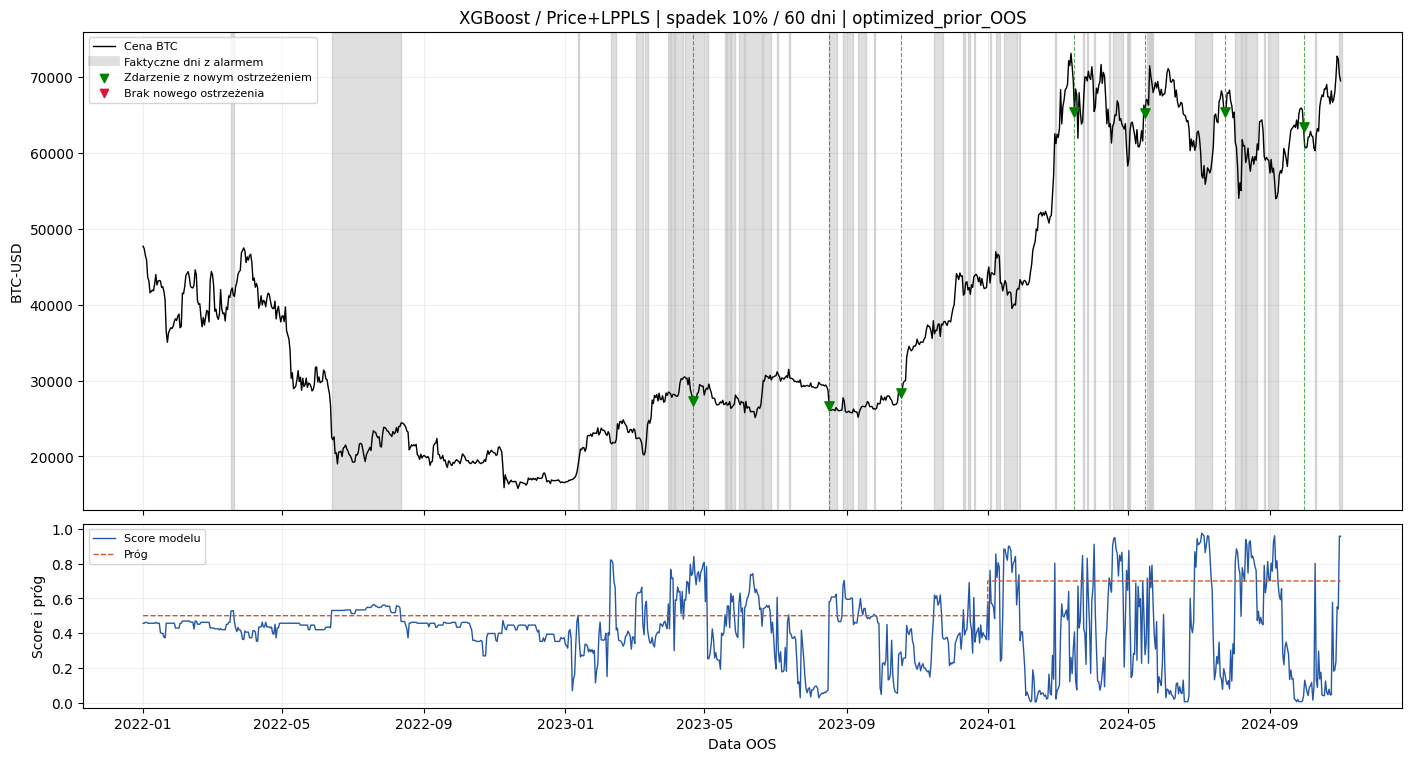

In [8]:
def plot_timeline(model,group,drop,H,strategy='optimized_prior_OOS'):
    t=test_daily_df.loc[(test_daily_df.model==model)&(test_daily_df.feature_group==group)
            &(test_daily_df.drop_pct==drop)&(test_daily_df.horizon==H)
            &(test_daily_df.strategy==strategy)].sort_values('date').copy()
    if t.empty:
        return
    fig,(ax,axs)=plt.subplots(2,1,figsize=(14,7.5),sharex=True,
                               gridspec_kw={'height_ratios':[2.6,1]},constrained_layout=True)
    p=prices.loc[prices.date.between(t.date.min(),t.date.max())]
    ax.plot(p.date,p.price,color='black',lw=1,label='Cena BTC')
    # Błąd z poprzedniego notatnika: NIE używamy cooldown do cieniowania.
    ints=active_intervals(t)
    for r in ints.itertuples(index=False):
        ax.axvspan(r.start,r.end+pd.Timedelta(days=1),color='gray',alpha=.25)
    ev=event_df.loc[(event_df.model==model)&(event_df.feature_group==group)
                &(event_df.drop_pct==drop)&(event_df.horizon==H)
                &(event_df.strategy==strategy)].drop_duplicates(['event_id','event_date'])
    for r in ev.itertuples(index=False):
        col='green' if r.hit_onset else 'crimson'
        ax.axvline(r.event_date,lw=.8,ls='--',color=col,alpha=.65)
        px=prices.loc[prices.date.eq(r.event_date),'price']
        if len(px):
            ax.scatter([r.event_date],[px.iloc[0]],marker='v',color=col,s=45,zorder=4)
    ax.plot([],[],lw=7,color='gray',alpha=.25,label='Faktyczne dni z alarmem')
    ax.scatter([],[],marker='v',color='green',label='Zdarzenie z nowym ostrzeżeniem')
    ax.scatter([],[],marker='v',color='crimson',label='Brak nowego ostrzeżenia')
    ax.set_ylabel('BTC-USD')
    ax.set_title(f'{model} / {group} | spadek {drop}% / {H} dni | {strategy}')
    ax.grid(alpha=.2)
    ax.legend(loc='upper left',fontsize=8)
    axs.plot(t.date,t.score,color='#2458a7',lw=1,label='Score modelu')
    axs.step(t.date,t.threshold.fillna(.5),where='post',ls='--',lw=1,color='#ce5a2a',label='Próg')
    axs.set_ylim(-.03,1.03)
    axs.set_ylabel('Score i próg')
    axs.set_xlabel('Data OOS')
    axs.grid(alpha=.2)
    axs.legend(loc='upper left',fontsize=8)
    name=f'10b_08_timeline_{model}_{group.replace("+","plus")}_{drop}_{H}.png'
    fig.savefig(OUT/name,dpi=175)
    plt.show()

plot_timeline(PLOT_MODEL,PLOT_FEATURE_GROUP,PLOT_DROP,PLOT_HORIZON)

## 8. Wykres B — kompromis między event recall i fałszywymi ostrzeżeniami

Rozmiar punktu odpowiada udziałowi dni w alarmie. Nie interpretuj pojedynczego
punktu jako dowodu przewagi bez sprawdzenia liczby zdarzeń i rocznych wyników.

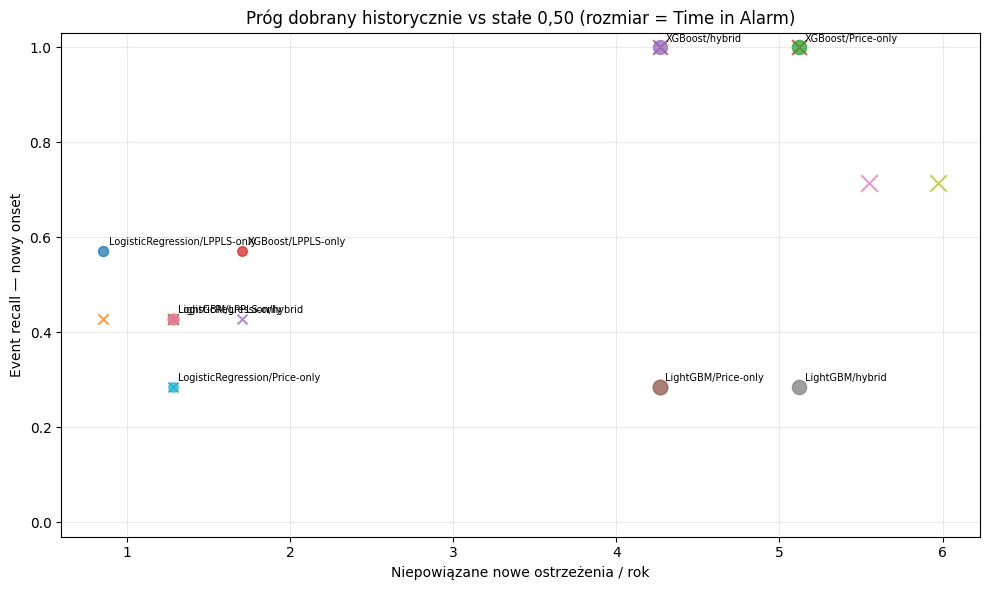

In [9]:
fig,ax=plt.subplots(figsize=(10,6))
tab=summary.loc[(summary.drop_pct==PLOT_DROP)&(summary.horizon==PLOT_HORIZON)
                &summary.strategy.isin(['optimized_prior_OOS','fixed_050'])]
for strategy,part in tab.groupby('strategy'):
    for _,r in part.iterrows():
        if not np.isfinite(r.event_recall_onset):
            continue
        ax.scatter(r.false_warnings_per_year,r.event_recall_onset,
                   s=35+260*r.time_in_alarm,alpha=.75,
                   marker='o' if strategy=='optimized_prior_OOS' else 'x')
        if strategy=='optimized_prior_OOS':
            ax.annotate(r.model+'/'+r.feature_group.replace('Price+LPPLS','hybrid'),
                        (r.false_warnings_per_year,r.event_recall_onset),
                        fontsize=7,xytext=(4,4),textcoords='offset points')
ax.set_xlabel('Niepowiązane nowe ostrzeżenia / rok')
ax.set_ylabel('Event recall — nowy onset')
ax.set_ylim(-.03,1.03)
ax.set_title('Próg dobrany historycznie vs stałe 0,50 (rozmiar = Time in Alarm)')
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(OUT/'10b_09_porownanie_strategii_event_based.png',dpi=180)
plt.show()

## 9. Diagnostyka wyboru progu: ostatni rok kalibracji

`selected` wskazuje, czy wybrano próg zgodny z ograniczeniami (`feasible`),
czy tylko wariant diagnostyczny (`infeasible_fallback`).

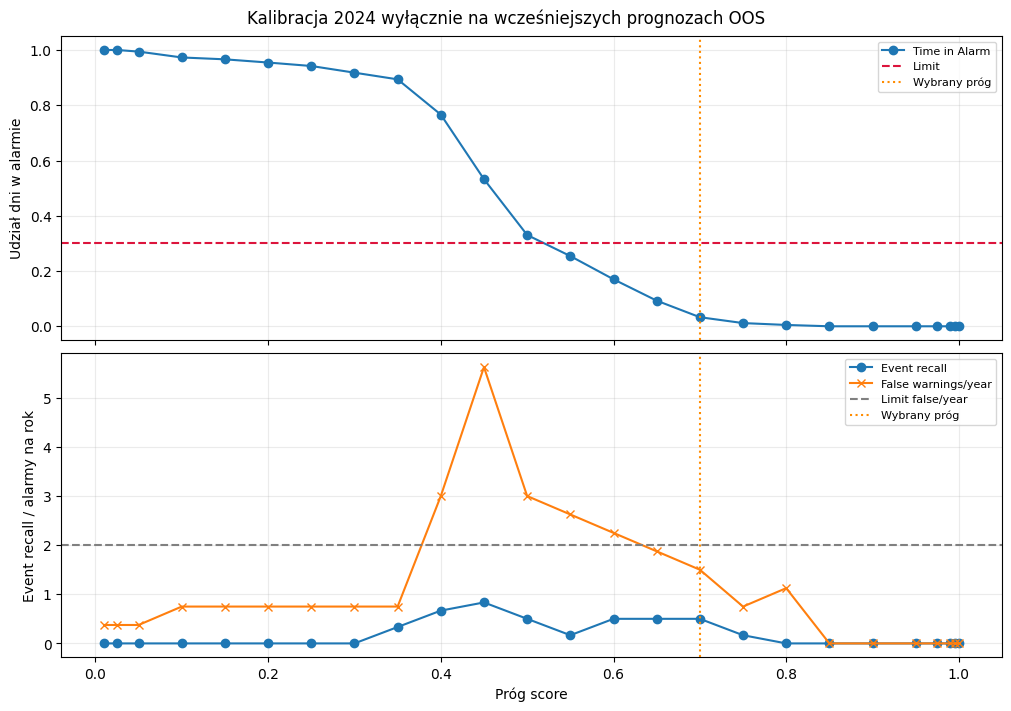

In [10]:
s=search_df.loc[(search_df.year==2024)&(search_df.drop_pct==PLOT_DROP)
                &(search_df.horizon==PLOT_HORIZON)&(search_df.model==PLOT_MODEL)
                &(search_df.feature_group==PLOT_FEATURE_GROUP)].sort_values('threshold')
if not s.empty:
    fig,(a,b)=plt.subplots(2,1,figsize=(10,7),sharex=True,constrained_layout=True)
    a.plot(s.threshold,s.time_in_alarm,marker='o',label='Time in Alarm')
    a.axhline(MAX_TIME_IN_ALARM,ls='--',color='crimson',label='Limit')
    b.plot(s.threshold,s.event_recall_onset,marker='o',label='Event recall')
    b.plot(s.threshold,s.false_warnings_per_year,marker='x',label='False warnings/year')
    b.axhline(MAX_FALSE_WARNINGS_YEAR,ls='--',color='gray',label='Limit false/year')
    chosen=s.loc[s.selected]
    if len(chosen):
        for ax in [a,b]:
            ax.axvline(chosen.iloc[0].threshold,color='darkorange',ls=':',label='Wybrany próg')
    for ax in [a,b]:
        ax.grid(alpha=.25);ax.legend(fontsize=8)
    a.set_ylabel('Udział dni w alarmie')
    b.set_ylabel('Event recall / alarmy na rok')
    b.set_xlabel('Próg score')
    fig.suptitle('Kalibracja 2024 wyłącznie na wcześniejszych prognozach OOS')
    fig.savefig(OUT/'10b_10_diagnostyka_progu_2024.png',dpi=175)
    plt.show()

## 10. Wnioski i kontrole przed publikacją

1. Rok 2021 jest *pierwszym OOS* z 08b; **nie ma możliwości** wyboru progu
   z wcześniejszych predykcji OOS bez generowania dodatkowych predykcji.
2. Jeśli kalibracja zawiera mniej niż MIN_CAL_EVENTS epizodów, stosujemy próg
   referencyjny 0,50 (nie udajemy, że próg został skalibrowany).
3. To podejście dobiera próg na wcześniejszych **OOS prognozach różnych rocznych
   modeli**. Jest poprawne w sensie dostępności informacji, ale zakłada, że
   rozkład wyniku `score` jest dostatecznie porównywalny między rocznymi wersjami
   modelu. Kalibrację score i ewentualny drift trzeba zbadać osobno.
4. Pod koniec roku wyłączamy H ostatnich dni z niepowiązanych ostrzeżeń; także
   zdarzenia w pierwszych H dniach roku nie mają pełnej historii prognoz z tej
   samej wersji modelu. W raportach prezentujemy mianowniki.
5. Próg jest wybierany względem zdarzeń *drawdown od maksimum 180d*, które
   nie są tożsame z etykietą `future_drop` z notatnika 07.
6. Rok 2021–2024 był już wielokrotnie analizowany w projekcie: wyniki te są
   **eksploracyjne** i nie mogą być przedstawiane jako niezależny finalny test.
7. Sprawdź stabilność dla `WARNING_COOLDOWN_DAYS` = 0, 7, 14 oraz definicji
   zdarzeń z lookback 90, 180, 365 i separacją 30, 60, 90 dni.
8. Kolejny etap: niezależny zbiór finalny + kalibracja score + analiza reżimów.

In [11]:
print('Zapisano pliki w:',OUT.resolve())
print('Statusy doboru progu:')
display(selected_df.groupby('selection_status').size().rename('liczba').reset_index())
print('Przykładowe porównanie:')
display(summary.loc[(summary.drop_pct==PLOT_DROP)&(summary.horizon==PLOT_HORIZON),
                    ['model','feature_group','strategy','n_events','event_recall_onset',
                     'false_warnings_per_year','time_in_alarm']].round(3).head(18))

Zapisano pliki w: C:\Users\cynar\Desktop\projects\lppls_article\wyniki_threshold_10b
Statusy doboru progu:


,selection_status,liczba
0,feasible,7
1,infeasible_fallback,2
2,insufficient_events_in_calibration,18


Przykładowe porównanie:


,model,feature_group,strategy,n_events,event_recall_onset,false_warnings_per_year,time_in_alarm
0,LogisticRegression,Price-only,optimized_prior_OOS,7,0.286,1.280,0.042
1,LogisticRegression,Price-only,fixed_050,7,0.286,1.280,0.055
2,LogisticRegression,Price-only,fixed_075,7,0.000,0.000,0.000
3,LogisticRegression,Price-only,original_08b,7,0.000,1.280,0.997
4,LogisticRegression,LPPLS-only,optimized_prior_OOS,7,0.571,0.853,0.068
5,LogisticRegression,LPPLS-only,fixed_050,7,0.429,0.853,0.078
6,LogisticRegression,LPPLS-only,fixed_075,7,0.429,1.280,0.021
7,LogisticRegression,LPPLS-only,original_08b,7,0.000,1.280,0.996
8,LogisticRegression,Price+LPPLS,optimized_prior_OOS,7,0.429,1.280,0.106
9,LogisticRegression,Price+LPPLS,fixed_050,7,0.429,1.280,0.106
